# SciPostLayout Dataset: Exploratory Data Analysis

## 1. Project Overview

This notebook explores the SciPostLayout v2 dataset for the Infographix AI-powered technical poster and infographic generator project.

## 2. Objectives

- Inspect dataset structure, image metadata, annotations, and layout categories.
- Validate dataset split counts, image references, IDs, and annotation bounding boxes.
- Analyze category distributions across training, development, and test splits.
- Examine image dimensions, aspect ratios, annotation density, and relative bounding-box areas.
- Visually inspect annotated posters to assess bounding-box and category-label alignment.

## 3. Dataset Splits

The dataset contains three splits: train, dev, and test. The notebook evaluates each split separately and compares their distributions.

## 4. Scope and Limitations

The analysis uses the provided JSON annotations and extracted poster images. Visual inspection is sample-based and does not establish that every annotation is correct. Invalid bounding boxes are measured using the validation rules implemented by the project's existing dataset loader.

## 5. Reproducibility

The environment is recorded in the project README. For library versions check `requirements.txt`.

The dataset is located in the directory `data/interim/scipostlayout/`.
The structure was described in the `README` that came with the dataset.
The structure of the dataset is depicted below:

```
scipostlayout/
├── poster/
│   ├── png/
│   │   ├── train.zip        # 6,855 poster images of train set.
│   │   ├── dev/             # 500 poster images of dev set.
│   │   ├── test/            # 500 poster images of test set.
│   │   ├── train.json       # annotation data of train set.
│   │   ├── dev.json         # annotation data of valid set.
│   │   ├── test.json        # annotation data of test set.
│   │   └── load_dataset.py  # example script to load the dataset.
│   └── pdf/                 # poster pdf files (optional).
└── paper/
    ├── pdf/                 # paper pdf files.
    ├── jpg/                 # paper jpg files.
    └── mmd/                 # mmd files of papers parsed with Nougat.
```

In [10]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# this notebook is running from the /notebooks directory, so the root is the parent
PROJECT_ROOT = Path.cwd().parent

# we choose to investigate the png images only.
DATA_ROOT = (
    PROJECT_ROOT
    / "data"
    / "interim"
    / "scipostlayout"
    / "poster"
    / "png"
)

print(DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())

/mnt/c/Users/rahul/Desktop/Projects/infographix/data/interim/scipostlayout/poster/png
Dataset exists: True


## 3. Dataset Loading and Overview.

In [5]:
# Load the three dataset splits
splits = {}

for split in ["train", "dev", "test"]:
    json_path = DATA_ROOT / f"{split}.json"

    with open(json_path, "r", encoding="utf-8") as f:
        splits[split] = json.load(f)

    print(f"{split.upper()} loaded successfully")

# Create DataFrames for easier analysis
images = {
    split: pd.DataFrame(data["images"])
    for split, data in splits.items()
}

annotations = {
    split: pd.DataFrame(data["annotations"])
    for split, data in splits.items()
}

categories = pd.DataFrame(splits["train"]["categories"])

print("\nDataset summary")
for split in splits:
    print(
        f"{split.upper()}: "
        f"{len(images[split]):,} images, "
        f"{len(annotations[split]):,} annotations"
    )

print("\nCategory definitions:")
display(categories[["id", "name", "supercategory"]])

TRAIN loaded successfully
DEV loaded successfully
TEST loaded successfully

Dataset summary
TRAIN: 6,855 images, 168,313 annotations
DEV: 500 images, 12,141 annotations
TEST: 500 images, 12,243 annotations

Category definitions:


,id,name,supercategory
0,674852286,Author Info,root
1,487601213,Title,root
2,3731383018,Figure,root
3,2871247081,Text,root
4,2837082304,List,root
5,481284670,Section,root
6,788514875,Caption,root
7,3405481596,Table,root
8,3591166397,Unknown,root


## 4. Dataset Integrity and Data Quality

This section checks image and annotation ID uniqueness, cross-split ID overlap, annotation references, physical image-file availability, missing metadata fields, duplicate filenames, and bounding-box validity.

In [6]:
# Check integrity within each split
integrity_results = {}

for split in ["train", "dev", "test"]:
    img_df = images[split]
    ann_df = annotations[split]

    image_ids = set(img_df["id"])
    annotation_ids = ann_df["id"]

    integrity_results[split] = {
        "images": len(img_df),
        "annotations": len(ann_df),
        "duplicate_image_ids": int(img_df["id"].duplicated().sum()),
        "duplicate_annotation_ids": int(annotation_ids.duplicated().sum()),
        "annotations_with_missing_image": int(
            (~ann_df["image_id"].isin(image_ids)).sum()
        ),
        "duplicate_filenames": int(img_df["file_name"].duplicated().sum()),
        "missing_image_files": int(
            sum(
                not (DATA_ROOT / split / filename).is_file()
                for filename in img_df["file_name"]
            )
        ),
    }

integrity_table = pd.DataFrame(integrity_results).T
display(integrity_table)

,images,annotations,duplicate_image_ids,duplicate_annotation_ids,annotations_with_missing_image,duplicate_filenames,missing_image_files
train,6855,168313,0,0,0,0,0
dev,500,12141,0,0,0,0,0
test,500,12243,0,0,0,0,0


In [7]:
# Summarize each dataset split
summary_rows = []

for split in ["train", "dev", "test"]:
    img_df = images[split]
    ann_df = annotations[split]

    summary_rows.append({
        "split": split,
        "images": len(img_df),
        "annotations": len(ann_df),
        "annotations_per_image": len(ann_df) / len(img_df),
        "median_width": img_df["width"].median(),
        "median_height": img_df["height"].median(),
        "min_width": img_df["width"].min(),
        "max_width": img_df["width"].max(),
        "min_height": img_df["height"].min(),
        "max_height": img_df["height"].max(),
    })

dataset_summary = pd.DataFrame(summary_rows)

display(
    dataset_summary.round(2)
)

,split,images,annotations,annotations_per_image,median_width,median_height,min_width,max_width,min_height,max_height
0,train,6855,168313,24.55,3312.0,4223.0,261,14762,355,14628
1,dev,500,12141,24.28,3312.0,4200.0,725,9000,460,7796
2,test,500,12243,24.49,3312.0,4646.0,497,11200,563,7539


## 5. Category Distribution Analysis

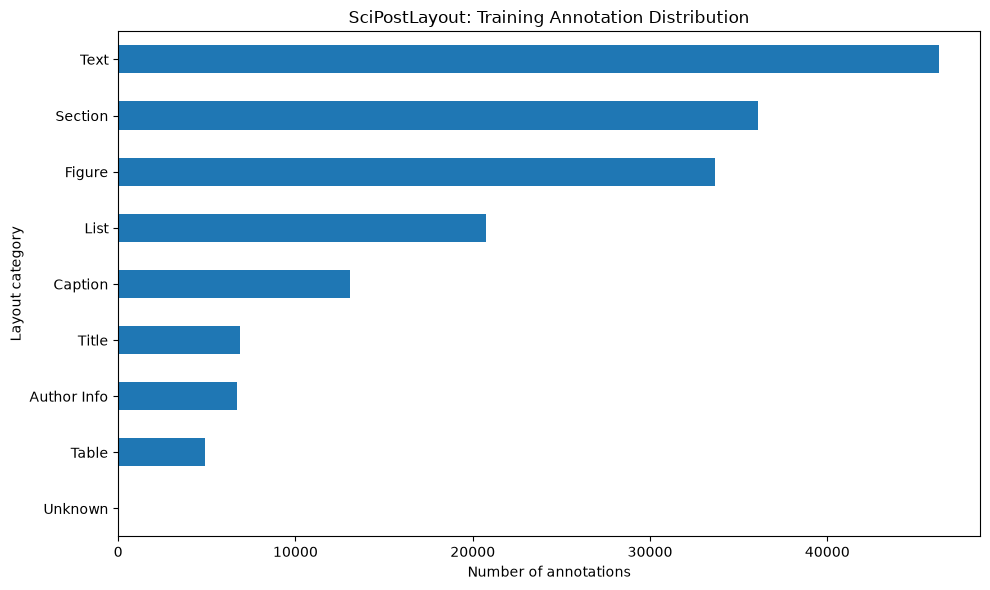

In [8]:
# Count annotations by category in each split
category_maps = {
    split: dict(zip(
        splits[split]["categories"][0:0] and [],
        []
    ))
    for split in []
}

category_names = {
    category["id"]: category["name"]
    for category in splits["train"]["categories"]
}

category_counts = {}

for split in ["train", "dev", "test"]:
    counts = annotations[split]["category_id"].map(
        category_names
    ).value_counts()

    category_counts[split] = counts

# Plot the training-set distribution
train_counts = category_counts["train"].sort_values()

plt.figure(figsize=(10, 6))
train_counts.plot(kind="barh")
plt.title("SciPostLayout: Training Annotation Distribution")
plt.xlabel("Number of annotations")
plt.ylabel("Layout category")
plt.tight_layout()
plt.show()

### Category Distribution Across Dataset Splits

,train,dev,test
category_id,,,
Author Info,3.99,4.05,4.03
Title,4.07,4.09,4.07
Figure,20.00,19.94,20.29
Text,27.51,26.48,26.13
List,12.31,12.26,12.93
Section,21.44,21.49,21.61
Caption,7.76,8.36,8.25
Table,2.92,3.30,2.68
Unknown,0.00,0.02,0.01


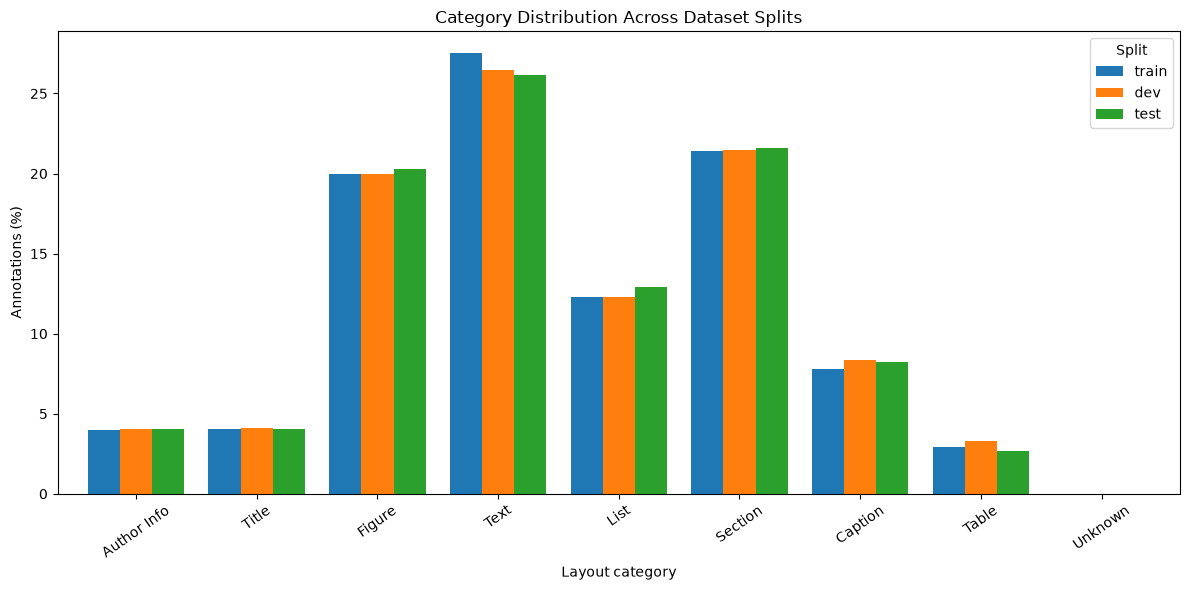

In [13]:
# Compare category percentages across train, dev and test
category_pct = pd.DataFrame({
    split: annotations[split]["category_id"]
        .map(category_names)
        .value_counts(normalize=True)
        .mul(100)
    for split in ["train", "dev", "test"]
}).fillna(0)

category_pct = category_pct.reindex(
    category_names.values()
)

display(category_pct.round(2))

ax = category_pct.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Category Distribution Across Dataset Splits")
ax.set_xlabel("Layout category")
ax.set_ylabel("Annotations (%)")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Split")
plt.tight_layout()
plt.show()

## 6. Image Dimensions and Orientation

This section examines image width, height, aspect ratios, and the distribution of portrait, square, and landscape posters across the train, dev, and test splits.

In [9]:
# Analyze image dimensions and orientation

dimension_rows = []

for split in ["train", "dev", "test"]:
    img_df = images[split]

    widths = img_df["width"]
    heights = img_df["height"]
    aspect_ratios = widths / heights

    dimension_rows.append({
        "split": split,
        "images": len(img_df),
        "min_width": widths.min(),
        "median_width": widths.median(),
        "max_width": widths.max(),
        "min_height": heights.min(),
        "median_height": heights.median(),
        "max_height": heights.max(),
        "min_aspect_ratio": aspect_ratios.min(),
        "median_aspect_ratio": aspect_ratios.median(),
        "max_aspect_ratio": aspect_ratios.max(),
        "portrait": int((aspect_ratios < 0.95).sum()),
        "square": int(
            ((aspect_ratios >= 0.95) & (aspect_ratios <= 1.05)).sum()
        ),
        "landscape": int((aspect_ratios > 1.05).sum()),
    })

dimension_summary = pd.DataFrame(dimension_rows)

display(dimension_summary.round(3))

,split,images,min_width,median_width,max_width,min_height,median_height,max_height,min_aspect_ratio,median_aspect_ratio,max_aspect_ratio,portrait,square,landscape
0,train,6855,261,3312.0,14762,355,4223.0,14628,0.223,0.750,3.099,4430,275,2150
1,dev,500,725,3312.0,9000,460,4200.0,7796,0.457,0.750,2.143,320,20,160
2,test,500,497,3312.0,11200,563,4646.0,7539,0.454,0.746,2.898,343,21,136


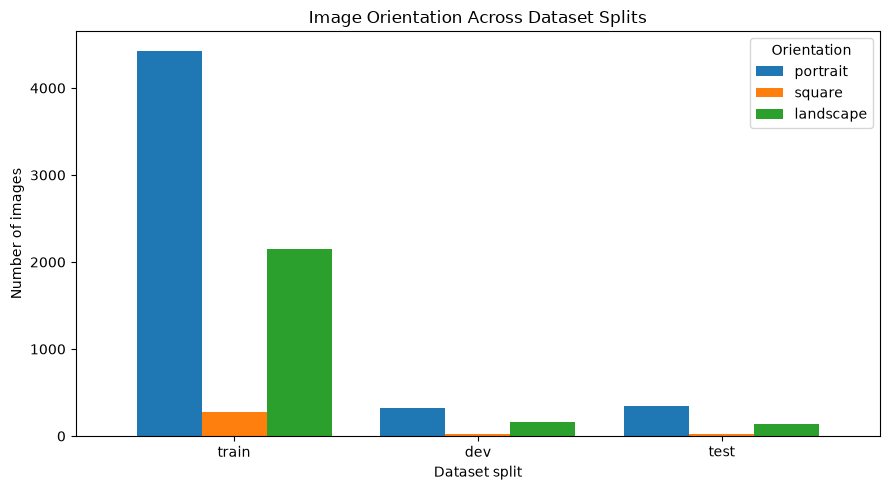

In [10]:
# Visualize image orientation across dataset splits

orientation_summary = dimension_summary.set_index("split")[
    ["portrait", "square", "landscape"]
]

ax = orientation_summary.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.8
)

ax.set_title("Image Orientation Across Dataset Splits")
ax.set_xlabel("Dataset split")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Orientation")

plt.tight_layout()
plt.show()

## 7. Annotation Density

This section analyzes the number of annotated layout elements per poster across the train, dev, and test splits. It examines the distribution, typical complexity, and number of posters containing more than 50 annotations.

In [11]:
# Analyze annotations per image

density_rows = []

for split in ["train", "dev", "test"]:
    img_df = images[split]
    ann_df = annotations[split]

    counts = ann_df["image_id"].value_counts()
    per_image = img_df["id"].map(counts).fillna(0)

    density_rows.append({
        "split": split,
        "min_annotations": int(per_image.min()),
        "median_annotations": per_image.median(),
        "mean_annotations": per_image.mean(),
        "max_annotations": int(per_image.max()),
        "zero_annotation_images": int((per_image == 0).sum()),
        "images_over_50_annotations": int((per_image > 50).sum()),
    })

density_summary = pd.DataFrame(density_rows)

display(density_summary.round(2))

,split,min_annotations,median_annotations,mean_annotations,max_annotations,zero_annotation_images,images_over_50_annotations
0,train,1,23.0,24.55,97,0,117
1,dev,1,23.0,24.28,64,0,4
2,test,1,23.0,24.49,64,0,14


## 8. Bounding-Box Statistics

This section examines the relative area occupied by individual annotated elements. Bounding-box areas are normalized by the corresponding image area. Invalid boxes are excluded using the dataset loader's bounding-box validity rules.

In [12]:
# Analyze relative bounding-box area

box_area_rows = []

for split in ["train", "dev", "test"]:
    img_df = images[split].set_index("id")
    ann_df = annotations[split]

    image_width = ann_df["image_id"].map(img_df["width"])
    image_height = ann_df["image_id"].map(img_df["height"])

    x = ann_df["bbox"].apply(lambda b: b[0])
    y = ann_df["bbox"].apply(lambda b: b[1])
    w = ann_df["bbox"].apply(lambda b: b[2])
    h = ann_df["bbox"].apply(lambda b: b[3])

    valid = (
        (x >= 0)
        & (y >= 0)
        & (w > 0)
        & (h > 0)
        & ((x + w) <= image_width)
        & ((y + h) <= image_height)
    )

    relative_area = (
        (w[valid] * h[valid])
        / (image_width[valid] * image_height[valid])
    ).sort_values().reset_index(drop=True)

    box_area_rows.append({
        "split": split,
        "valid_boxes": len(relative_area),
        "p25_area_pct": relative_area.quantile(0.25) * 100,
        "median_area_pct": relative_area.quantile(0.50) * 100,
        "p75_area_pct": relative_area.quantile(0.75) * 100,
        "p95_area_pct": relative_area.quantile(0.95) * 100,
        "mean_area_pct": relative_area.mean() * 100,
    })

box_area_summary = pd.DataFrame(box_area_rows)

display(box_area_summary.round(3))

,split,valid_boxes,p25_area_pct,median_area_pct,p75_area_pct,p95_area_pct,mean_area_pct
0,train,168220,0.301,1.428,3.502,8.291,2.505
1,dev,12136,0.333,1.486,3.616,8.607,2.576
2,test,12241,0.320,1.442,3.601,8.577,2.548


## 9. Visual Inspection of Annotations

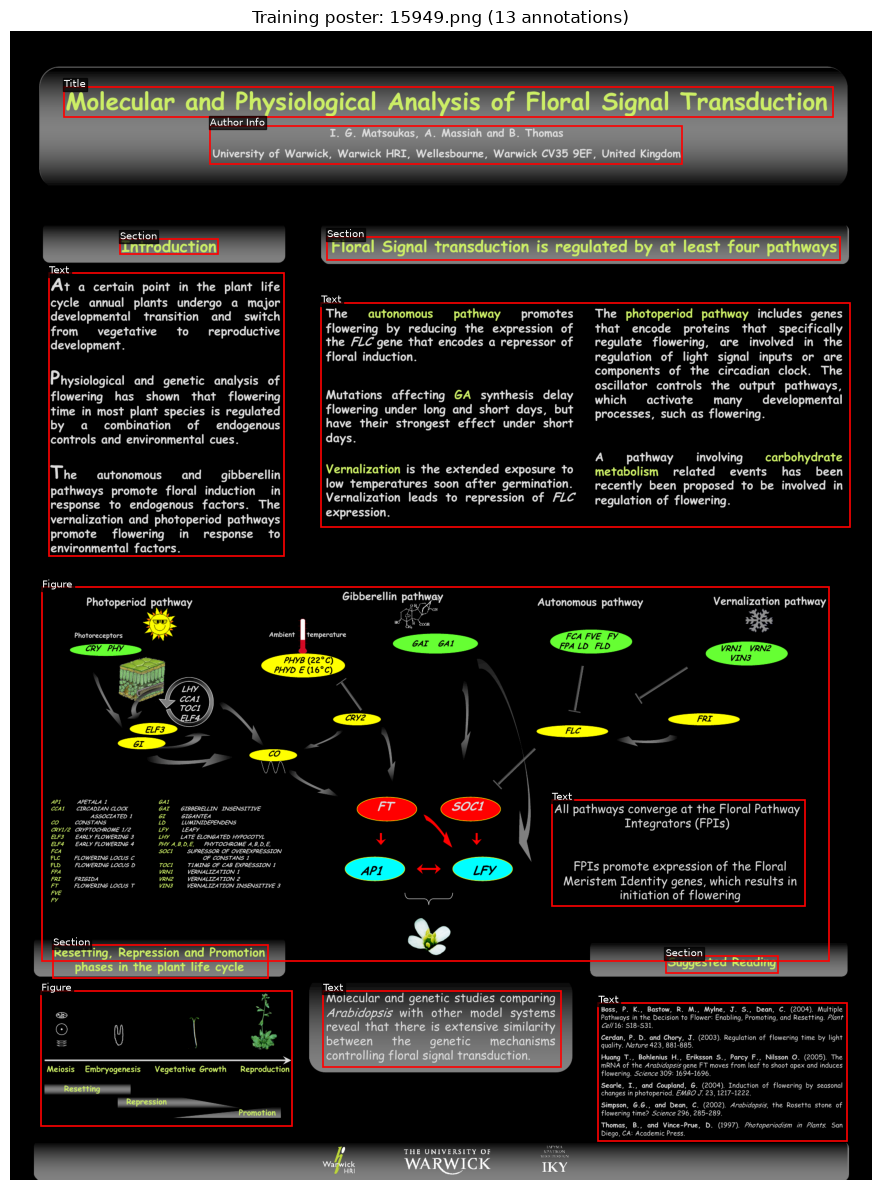

Image: 15949.png
Image dimensions: (1800, 2400)
Annotations: 13


In [14]:
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

# Pick one poster that has valid annotations
split = "train"
img_df = images[split]
ann_df = annotations[split]

# Use a fixed seed so the example is reproducible
rng = random.Random(42)
image_ids = img_df["id"].tolist()
rng.shuffle(image_ids)

selected_id = None
selected_annotations = None

for image_id in image_ids:
    img_anns = ann_df[ann_df["image_id"] == image_id]

    if len(img_anns) > 0:
        selected_id = image_id
        selected_annotations = img_anns
        break

image_info = img_df[img_df["id"] == selected_id].iloc[0]
image_path = DATA_ROOT / "train" / image_info["file_name"]

with Image.open(image_path) as im:
    poster = im.convert("RGB")

fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(poster)

category_names = {
    category["id"]: category["name"]
    for category in splits[split]["categories"]
}

for _, ann in selected_annotations.iterrows():
    x, y, w, h = ann["bbox"]
    category = category_names.get(ann["category_id"], "Unknown")

    # Skip invalid boxes for visualization
    if x < 0 or y < 0 or w <= 0 or h <= 0:
        continue
    if x + w > poster.width or y + h > poster.height:
        continue

    rect = patches.Rectangle(
        (x, y), w, h,
        fill=False,
        edgecolor="red",
        linewidth=1.2
    )
    ax.add_patch(rect)
    ax.text(
        x, y,
        category,
        color="white",
        fontsize=7,
        bbox=dict(facecolor="black", alpha=0.7, pad=1)
    )

ax.set_title(
    f"Training poster: {image_info['file_name']} "
    f"({len(selected_annotations)} annotations)"
)
ax.axis("off")
plt.tight_layout()
plt.show()

print("Image:", image_info["file_name"])
print("Image dimensions:", poster.size)
print("Annotations:", len(selected_annotations))

### Multiple Poster Samples

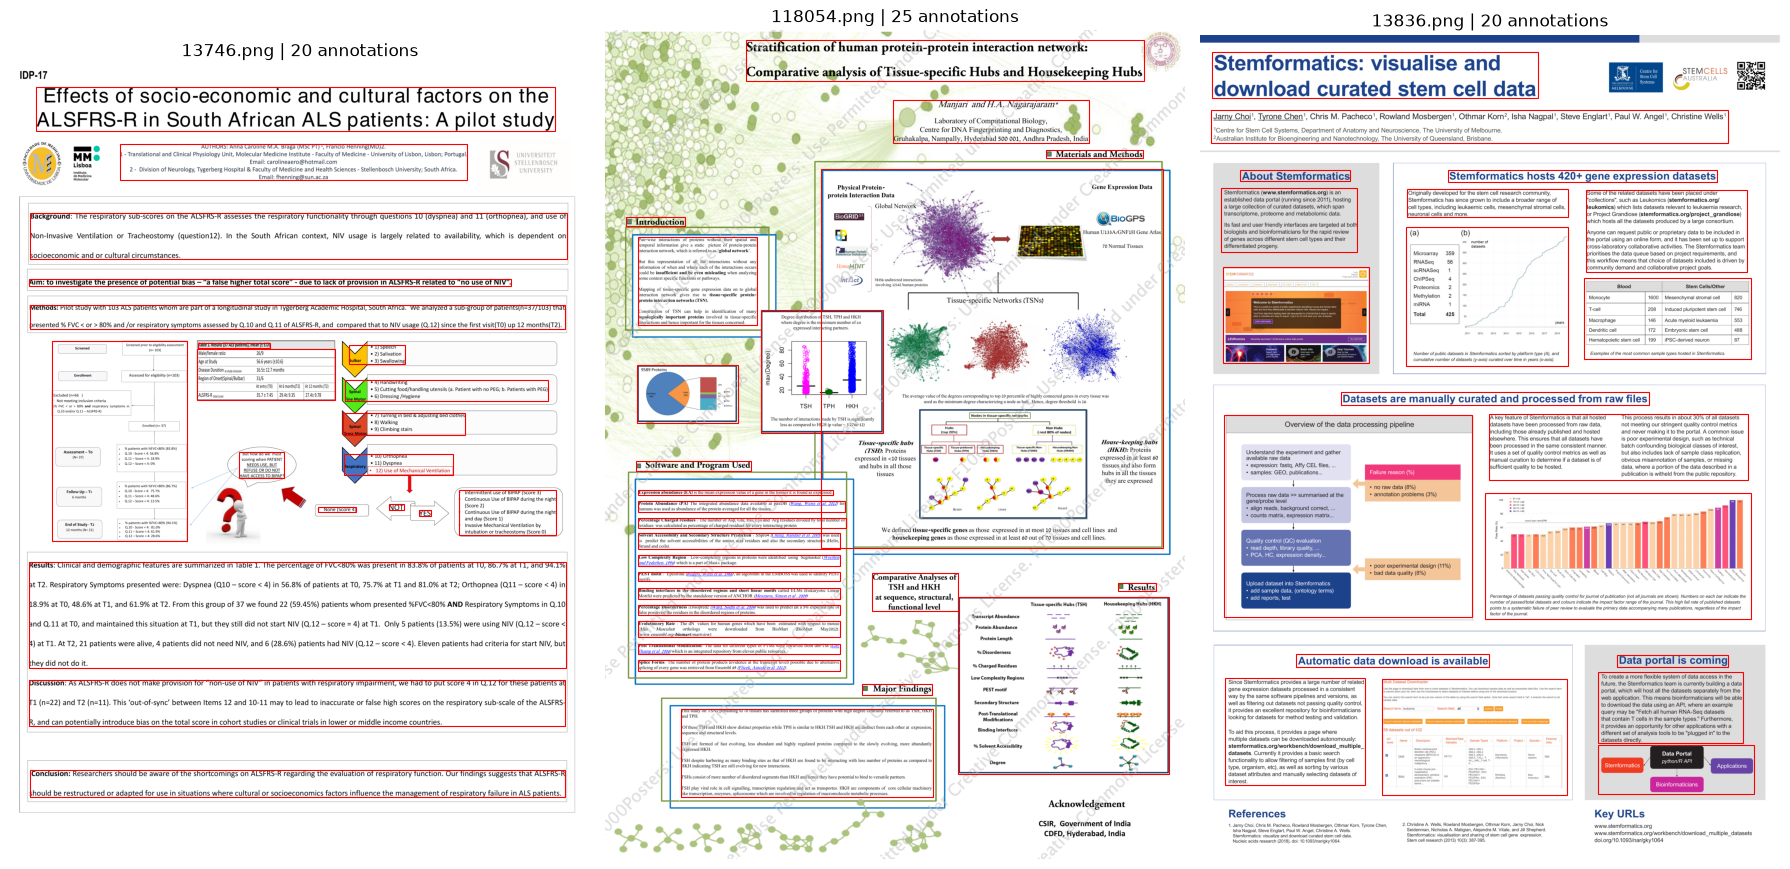

In [15]:
import random
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Reproducible sample of three training images
rng = random.Random(7)
sample_ids = rng.sample(images["train"]["id"].tolist(), 3)

fig, axes = plt.subplots(1, 3, figsize=(18, 10))

for ax, image_id in zip(axes, sample_ids):
    info = images["train"].loc[
        images["train"]["id"] == image_id
    ].iloc[0]

    path = DATA_ROOT / "train" / info["file_name"]

    with Image.open(path) as im:
        poster = im.convert("RGB")

    anns = annotations["train"].loc[
        annotations["train"]["image_id"] == image_id
    ]

    ax.imshow(poster)

    for _, ann in anns.iterrows():
        x, y, w, h = ann["bbox"]

        if (
            x < 0 or y < 0 or w <= 0 or h <= 0
            or x + w > poster.width
            or y + h > poster.height
        ):
            continue

        ax.add_patch(
            patches.Rectangle(
                (x, y), w, h,
                fill=False,
                edgecolor="red",
                linewidth=0.8
            )
        )

    ax.set_title(f"{info['file_name']} | {len(anns)} annotations")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Key Findings and Limitations

### Dataset Overview
- The SciPostLayout dataset contains **7,855 images and 192,697 annotations** across the training, development, and test splits.
- The dataset defines **nine layout categories**.

### Data Quality
- No duplicate image IDs or annotation IDs were detected within any split.
- No image ID or annotation ID overlap was detected across splits.
- All referenced image files were found in their expected directories.
- The existing dataset loader's bounding-box validation rules reject **100 annotations**: 93 from train, 5 from dev, and 2 from test.
- No missing required fields or duplicate filenames were detected in the checks performed.

### Category Distribution
- **Text** is the most frequent category, followed by **Section** and **Figure**.
- Category percentages are broadly similar across the train, dev, and test splits.
- `Unknown` annotations are extremely rare.

### Image and Layout Characteristics
- Approximately **64.6% of training images are portrait-oriented**, using the orientation thresholds defined in this notebook.
- The median annotation count is **23 per image** across all three splits.
- The median relative bounding-box area is approximately **1.4–1.5%** across the splits.

### Limitations
- Visual inspection was sample-based; not every image or annotation was examined manually.
- Category-distribution similarity was assessed descriptively, without a formal statistical test.
- Bounding-box rejection counts are annotation-level results and do not capture every image-level filtering decision made by the loader.
- Relative bounding-box areas describe individual boxes, not the total area covered by all poster elements.
- This analysis describes the dataset and does not establish model performance.